In [4]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['species'] = iris.target

df['species'] = df['species'].map({
    0: 'Setosa',
    1: 'Versicolor',
    2: 'Virginica'
})

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  Setosa  
1  Setosa  
2  Setosa  
3  Setosa  
4  Setosa  


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2

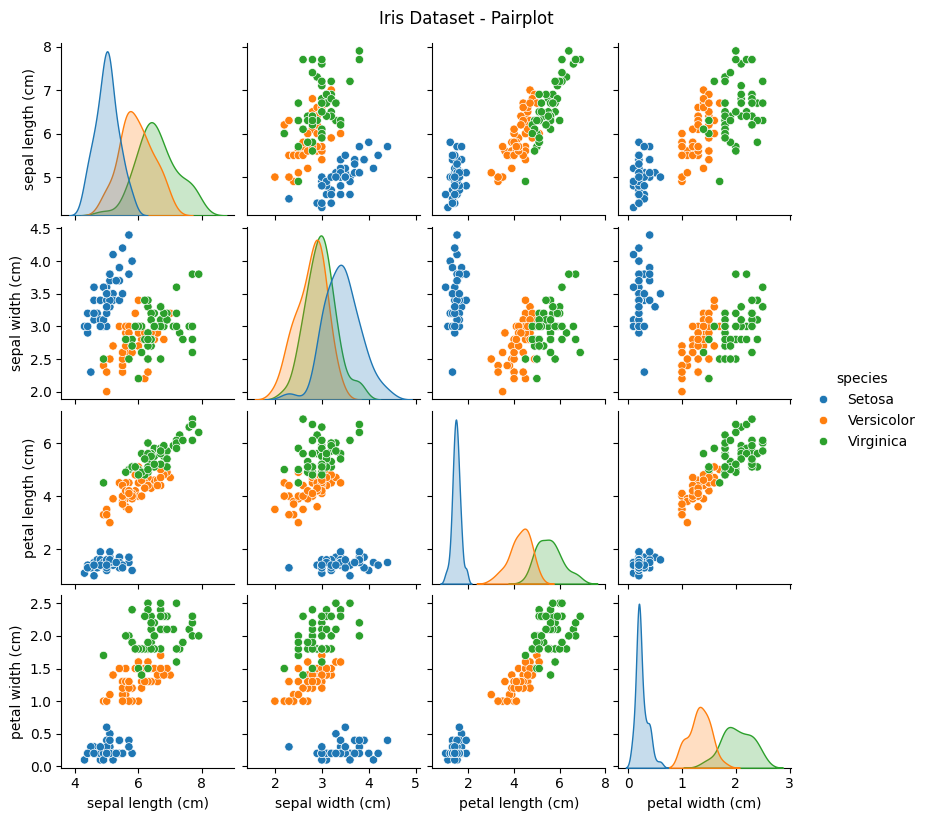

In [5]:
sns.pairplot(df, hue='species', height=2)

plt.suptitle("Iris Dataset - Pairplot", y=1.02)

plt.show()

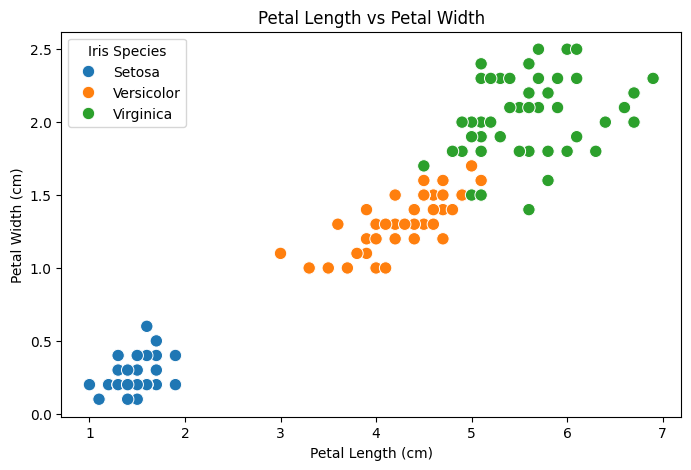

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species',
    s=80
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend(title="Iris Species")

plt.show()

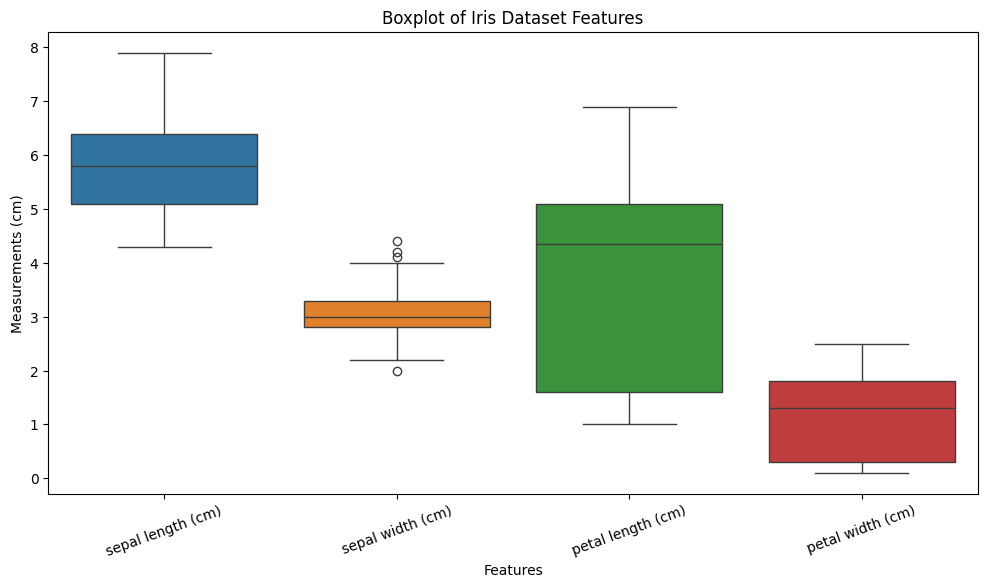

In [7]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df.drop(columns='species'))

plt.title("Boxplot of Iris Dataset Features")
plt.xlabel("Features")
plt.ylabel("Measurements (cm)")
plt.xticks(rotation=20)

plt.show()

In [8]:
X = df.drop('species', axis=1)
y = df['species']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training samples: 120
Testing samples: 30
Training data shape: (120, 4)
Testing data shape: (30, 4)


In [9]:
log_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=200))
])

log_model.fit(X_train, y_train)

log_predictions = log_model.predict(X_test)

log_accuracy = accuracy_score(y_test, log_predictions)

print("Logistic Regression Accuracy:",
      round(log_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 93.33 %


In [10]:
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

knn_predictions = knn_model.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 93.33 %


In [11]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 93.33 %


In [12]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 90.0 %


In [13]:
models = {
    'Logistic Regression': log_model,
    'KNN': knn_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy * 100, 2)
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by='Accuracy (%)',
    ascending=False
))

                 Model  Accuracy (%)
0  Logistic Regression         93.33
1                  KNN         93.33
2        Decision Tree         93.33
3        Random Forest         90.00


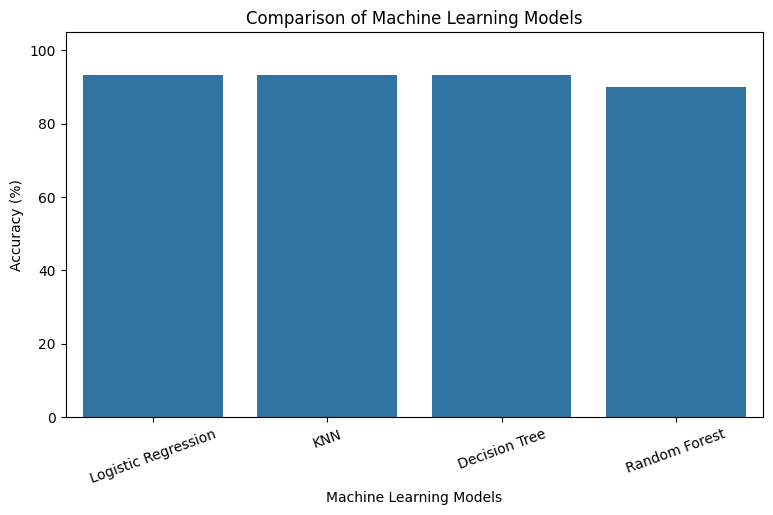

In [14]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy (%)'
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=20)
plt.ylim(0, 105)

plt.show()

In [15]:
from sklearn.metrics import f1_score

evaluation_results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    f1 = f1_score(
        y_test,
        predictions,
        average='macro'
    )

    evaluation_results.append({
        'Model': name,
        'Accuracy': accuracy * 100,
        'Macro F1-Score': f1
    })

evaluation_df = pd.DataFrame(evaluation_results)

print(evaluation_df.sort_values(
    by=['Accuracy', 'Macro F1-Score'],
    ascending=False
))

                 Model   Accuracy  Macro F1-Score
0  Logistic Regression  93.333333        0.933333
2        Decision Tree  93.333333        0.933333
1                  KNN  93.333333        0.932660
3        Random Forest  90.000000        0.899749


In [16]:
best_model_name = evaluation_df.sort_values(
    by=['Accuracy', 'Macro F1-Score'],
    ascending=False
).iloc[0]['Model']

best_model = models[best_model_name]

print("Best Performing Model:", best_model_name)

Best Performing Model: Logistic Regression


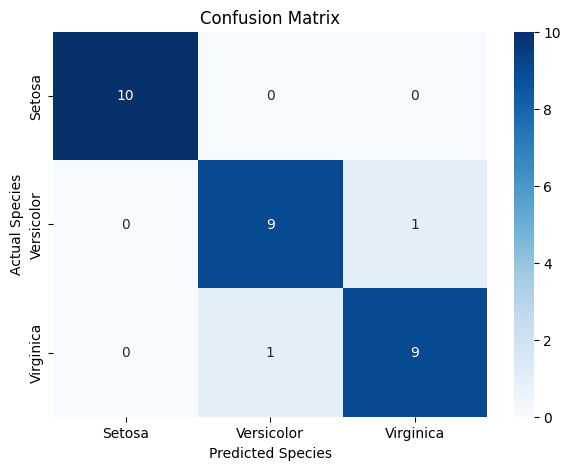

In [17]:
best_predictions = best_model.predict(X_test)
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=['Setosa', 'Versicolor', 'Virginica']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Setosa', 'Versicolor', 'Virginica'],
    yticklabels=['Setosa', 'Versicolor', 'Virginica']
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix")

plt.show()

In [18]:
print("Classification Report for", best_model_name)

print(classification_report(
    y_test,
    best_predictions
))

Classification Report for Logistic Regression
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.90      0.90      0.90        10
   Virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [19]:
final_accuracy = accuracy_score(
    y_test,
    best_predictions
)

print("Best Model:", best_model_name)

print("Final Accuracy:",
      round(final_accuracy * 100, 2), "%")

Best Model: Logistic Regression
Final Accuracy: 93.33 %


In [20]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = best_model.predict(new_flower)

print("New Flower Measurements:")
print(new_flower)

print("\nPredicted Flower Species:", prediction[0])

New Flower Measurements:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2

Predicted Flower Species: Setosa
